# Yachida CRC — MOFA+ and XGBoost

train early stages Xgboost model.Compares direct multi-omic XGBoost models with XGBoost models trained on MOFA+ latent factors.

    Healthy_vs_Stage_0
    Healthy_vs_Stage_I_II
    Healthy_vs_Early_CRC(Stage_0 + Stage_I_II)

## 1. setup

In [1]:
from pathlib import Path
import importlib.util
import os
import re
import shutil
import subprocess
import sys
import urllib.request
import warnings
import zipfile

try:
    from IPython.display import display
except Exception:
    display = print

try:
    from google.colab import files as colab_files
    IN_COLAB = True
except Exception:
    colab_files = None
    IN_COLAB = False

PROJECT_ROOT = Path(
    os.environ.get("YACHIDA_PROJECT_ROOT", "/content" if IN_COLAB else Path.cwd())
).expanduser().resolve()
PROJECT_ROOT.mkdir(parents=True, exist_ok=True)


def ensure_optional_package(module_name, pip_name=None):

    if importlib.util.find_spec(module_name) is not None:
        return True
    if not IN_COLAB:
        return False
    pip_name = pip_name or module_name
    try:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pip_name])
    except Exception as exc:
        print(f"[WARNING] Could not install optional package {pip_name!r}: {exc}")
        return False
    return importlib.util.find_spec(module_name) is not None

FAST_MODE = os.environ.get("YACHIDA_FAST_TEST", "0") == "1"

warnings.filterwarnings("ignore")
print(f"Runtime: {'Google Colab' if IN_COLAB else 'local Jupyter/Python'}")
print(f"Project root: {PROJECT_ROOT}")

Runtime: Google Colab
Project root: /content


In [2]:
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.stats import mannwhitneyu
from statsmodels.stats.multitest import multipletests
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

RANDOM_STATE = 42
TARGET_PAIRED_N = 347
PREVALENCE_THRESHOLD = 0.05
MIN_MEAN_REL_ABUNDANCE = 1e-6
TAXA_PSEUDOCOUNT = 1e-6
METABOLITE_PSEUDOCOUNT = 1.0
FDR_THRESHOLD = 0.05
LOG2FC_THRESHOLD = 0.5

pd.set_option("display.max_columns", 200)
pd.set_option("display.width", 200)


OUT_DIR = PROJECT_ROOT / "01_Yachida_MOFA_XGBoost_results"
FIG_DIR = OUT_DIR / "figures"
TABLE_DIR = OUT_DIR / "tables"
ML_DIR = OUT_DIR / "ml_results"
for directory in [OUT_DIR, FIG_DIR, TABLE_DIR, ML_DIR]:
    directory.mkdir(parents=True, exist_ok=True)
print(f"Output directory: {OUT_DIR}")

Output directory: /content/01_Yachida_MOFA_XGBoost_results


## 2. Independent data loading and preprocessing

In [3]:
# Download, load, match, and preprocess the Yachida data independently.
REPO_URL = "https://github.com/borenstein-lab/microbiome-metabolome-curated-data.git"
REPO_NAME = "microbiome-metabolome-curated-data"
REPO_DIR = PROJECT_ROOT / REPO_NAME
DEFAULT_DATA_DIR = REPO_DIR / "data" / "processed_data" / "YACHIDA_CRC_2019"


def _download_repository_with_zip(destination):
    for branch in ("master", "main"):
        url = f"https://github.com/borenstein-lab/{REPO_NAME}/archive/refs/heads/{branch}.zip"
        archive = PROJECT_ROOT / f"{REPO_NAME}-{branch}.zip"
        extracted = PROJECT_ROOT / f"{REPO_NAME}-{branch}"
        try:
            print(f"[INFO] Downloading repository ZIP from {url}")
            urllib.request.urlretrieve(url, archive)
            with zipfile.ZipFile(archive) as zf:
                zf.extractall(PROJECT_ROOT)
            if destination.exists():
                shutil.rmtree(destination)
            extracted.rename(destination)
            archive.unlink(missing_ok=True)
            return
        except Exception as exc:
            print(f"[WARNING] ZIP download for branch {branch!r} failed: {exc}")
            archive.unlink(missing_ok=True)
            if extracted.exists():
                shutil.rmtree(extracted)
    raise RuntimeError(
        "The public Yachida repository could not be downloaded. "
        "Check the runtime's internet connection, or set environment variable "
        "YACHIDA_DATA_DIR to a local YACHIDA_CRC_2019 folder."
    )


def resolve_data_dir():
    override = os.environ.get("YACHIDA_DATA_DIR")
    if override:
        data_dir = Path(override).expanduser().resolve()
        if not data_dir.exists():
            raise FileNotFoundError(f"YACHIDA_DATA_DIR does not exist: {data_dir}")
        print(f"[INFO] Using data directory from YACHIDA_DATA_DIR: {data_dir}")
        return data_dir

    if DEFAULT_DATA_DIR.exists():
        print(f"[INFO] Using existing repository data: {DEFAULT_DATA_DIR}")
        return DEFAULT_DATA_DIR

    if REPO_DIR.exists() and not DEFAULT_DATA_DIR.exists():
        print(f"[WARNING] Removing incomplete repository folder: {REPO_DIR}")
        shutil.rmtree(REPO_DIR)

    git_executable = shutil.which("git")
    if git_executable:
        try:
            print(f"[INFO] Cloning public repository into {REPO_DIR}")
            subprocess.run(
                [git_executable, "clone", "--depth", "1", REPO_URL, str(REPO_DIR)],
                cwd=PROJECT_ROOT,
                check=True,
            )
        except Exception as exc:
            print(f"[WARNING] git clone failed: {exc}")

    if not DEFAULT_DATA_DIR.exists():
        _download_repository_with_zip(REPO_DIR)

    if not DEFAULT_DATA_DIR.exists():
        raise FileNotFoundError(f"Dataset directory was not found after download: {DEFAULT_DATA_DIR}")
    return DEFAULT_DATA_DIR


DATA_DIR = resolve_data_dir()


def _clean_labels(values):
    return pd.Index([str(value).strip() for value in values])


def read_metadata(path):
    raw = pd.read_csv(path, sep="\t", low_memory=False)
    if raw.empty:
        raise ValueError(f"Metadata file is empty: {path}")

    normalized = {re.sub(r"[^a-z0-9]", "", str(col).lower()): col for col in raw.columns}
    sample_candidates = ["sample", "sampleid", "sampleidentifier", "id"]
    sample_col = next((normalized[key] for key in sample_candidates if key in normalized), None)

    if sample_col is None:
        # The curated Yachida metadata historically stores sample IDs in the second column.
        sample_col = raw.columns[1] if raw.shape[1] >= 2 else raw.columns[0]
        print(f"[WARNING] No standard sample-ID column name found; using {sample_col!r}.")

    raw[sample_col] = raw[sample_col].astype(str).str.strip()
    meta = raw.drop_duplicates(subset=[sample_col], keep="first").set_index(sample_col)
    meta.index.name = "Sample_ID"

    normalized_meta = {re.sub(r"[^a-z0-9]", "", str(col).lower()): col for col in meta.columns}
    group_candidates = ["studygroup", "group", "diseasegroup", "condition", "diagnosis"]
    group_col = next((normalized_meta[key] for key in group_candidates if key in normalized_meta), None)
    if group_col is None:
        raise KeyError(
            "No clinical group column was found. Expected a column such as "
            "'Study.Group', 'Group', 'Condition', or 'Diagnosis'."
        )
    return meta, group_col


def canonicalize_group(value):
    if pd.isna(value):
        return np.nan
    text = re.sub(r"[^a-z0-9]+", "", str(value).strip().lower())
    if text in {"healthy", "control", "controls", "normal", "hc"}:
        return "Healthy"
    if text in {"stage0", "s0", "crcstage0"}:
        return "Stage_0"
    if text in {"stageiii", "stage12", "siii", "s12", "stage1and2", "stageiandii"}:
        return "Stage_I_II"
    if text in {"stageiiiiv", "stage34", "siiiiv", "s34", "stage3and4", "stageiiiandiv"}:
        return "Stage_III_IV"
    return str(value).strip()


def read_feature_table(path, metadata_ids, duplicate_policy="sum"):
    frame = pd.read_csv(path, sep="\t", index_col=0, compression="infer", low_memory=False)
    frame.index = _clean_labels(frame.index)
    frame.columns = _clean_labels(frame.columns)
    metadata_ids = set(map(str, metadata_ids))

    index_overlap = len(set(frame.index) & metadata_ids)
    column_overlap = len(set(frame.columns) & metadata_ids)
    if column_overlap > index_overlap:
        frame = frame.T
        frame.index = _clean_labels(frame.index)
        frame.columns = _clean_labels(frame.columns)
        index_overlap = column_overlap

    if index_overlap == 0:
        raise ValueError(
            f"No sample IDs in {path.name} overlap the metadata. "
            "The table orientation or sample-ID format is not recognized."
        )

    frame = frame.loc[~frame.index.duplicated(keep="first")]
    if frame.columns.duplicated().any():
        grouped = frame.T.groupby(level=0)
        frame = grouped.mean().T if duplicate_policy == "mean" else grouped.sum().T
    return frame.apply(pd.to_numeric, errors="coerce")


def first_existing(*paths):
    for path in paths:
        if path.exists():
            return path
    raise FileNotFoundError("None of the required alternatives exists: " + ", ".join(map(str, paths)))


required_core = [DATA_DIR / "metadata.tsv", DATA_DIR / "mtb.tsv"]
missing_core = [path.name for path in required_core if not path.exists()]
if missing_core:
    raise FileNotFoundError(f"Missing required Yachida files: {missing_core} in {DATA_DIR}")

metadata_raw, ORIGINAL_GROUP_COL = read_metadata(DATA_DIR / "metadata.tsv")
metadata_raw["Group_Original"] = metadata_raw[ORIGINAL_GROUP_COL].astype(str)
metadata_raw["Group_Canonical"] = metadata_raw[ORIGINAL_GROUP_COL].map(canonicalize_group)
GROUP_COL = "Group_Canonical"
metadata_ids = set(metadata_raw.index.astype(str))

species_path = first_existing(DATA_DIR / "species.counts.tsv", DATA_DIR / "species.tsv.zip")
genera_path = first_existing(DATA_DIR / "genera.counts.tsv", DATA_DIR / "genera.tsv")
metabolomics_path = DATA_DIR / "mtb.tsv"

species_raw = read_feature_table(species_path, metadata_ids, duplicate_policy="sum")
genera_raw = read_feature_table(genera_path, metadata_ids, duplicate_policy="sum")
metabolomics_raw = read_feature_table(metabolomics_path, metadata_ids, duplicate_policy="mean")

sample_sets = {
    "metadata": set(metadata_raw.index),
    "species": set(species_raw.index),
    "genera": set(genera_raw.index),
    "metabolomics": set(metabolomics_raw.index),
}
paired_ids = sorted(set.intersection(*sample_sets.values()))
if not paired_ids:
    raise ValueError("No samples are shared across metadata, species, genera, and metabolomics.")

metadata = metadata_raw.loc[paired_ids].copy()
species_counts = species_raw.loc[paired_ids].copy()
genera_counts = genera_raw.loc[paired_ids].copy()
metabolomics = metabolomics_raw.loc[paired_ids].copy()

if len(paired_ids) != TARGET_PAIRED_N:
    print(f"[WARNING] Expected {TARGET_PAIRED_N} paired samples from the published curated set; found {len(paired_ids)}.")
else:
    print(f"[OK] Found the expected {TARGET_PAIRED_N} paired samples.")

sample_audit = pd.DataFrame({
    "Layer": list(sample_sets),
    "Samples_Loaded": [len(sample_sets[name]) for name in sample_sets],
    "Samples_In_Paired_Cohort": len(paired_ids),
})
sample_audit.to_csv(TABLE_DIR / "sample_id_audit_summary.csv", index=False)

master_mapping = metadata[["Group_Original", GROUP_COL]].copy()
master_mapping.insert(0, "Sample_ID", master_mapping.index)
master_mapping.to_csv(TABLE_DIR / "master_sample_mapping.csv", index=False)


def preprocess_taxonomy(counts):
    numeric = counts.apply(pd.to_numeric, errors="coerce").fillna(0.0).clip(lower=0.0)
    totals = numeric.sum(axis=1).replace(0.0, np.nan)
    relative = numeric.div(totals, axis=0).fillna(0.0)
    prevalence = (relative > 0).mean(axis=0)
    mean_abundance = relative.mean(axis=0)
    keep = (prevalence >= PREVALENCE_THRESHOLD) & (mean_abundance >= MIN_MEAN_REL_ABUNDANCE)
    if not keep.any():
        keep.loc[mean_abundance.nlargest(min(10, len(mean_abundance))).index] = True
    filtered = relative.loc[:, keep].copy()
    log_frame = np.log10(filtered + TAXA_PSEUDOCOUNT)
    scaled = pd.DataFrame(
        StandardScaler().fit_transform(log_frame),
        index=log_frame.index,
        columns=log_frame.columns,
    )
    return {"raw": numeric, "relative": relative, "filtered": filtered, "log": log_frame, "scaled": scaled}


def preprocess_metabolomics(frame):
    numeric = frame.apply(pd.to_numeric, errors="coerce")
    keep = numeric.notna().mean(axis=0).ge(0.20) & numeric.var(axis=0, skipna=True).fillna(0).gt(0)
    if not keep.any():
        keep.loc[numeric.notna().mean(axis=0).nlargest(min(10, numeric.shape[1])).index] = True
    filtered = numeric.loc[:, keep].copy()
    log_frame = np.log10(filtered.clip(lower=0.0) + METABOLITE_PSEUDOCOUNT)
    medians = log_frame.median(axis=0, skipna=True)
    imputed = log_frame.fillna(medians).fillna(0.0)
    scaled = pd.DataFrame(
        StandardScaler().fit_transform(imputed),
        index=imputed.index,
        columns=imputed.columns,
    )
    return {"raw": numeric, "filtered": filtered, "log": log_frame, "imputed": imputed, "scaled": scaled}


species_prep = preprocess_taxonomy(species_counts)
genera_prep = preprocess_taxonomy(genera_counts)
metabolomics_prep = preprocess_metabolomics(metabolomics)

data_blocks = {
    "species": species_prep["scaled"],
    "genera": genera_prep["scaled"],
    "metabolomics": metabolomics_prep["scaled"],
}
differential_blocks = {
    "species": species_prep["filtered"],
    "genera": genera_prep["filtered"],
    "metabolomics": metabolomics_prep["filtered"],
}
ml_blocks = {
    "species": species_prep["log"].add_prefix("species|"),
    "genera": genera_prep["log"].add_prefix("genera|"),
    "metabolomics": metabolomics_prep["imputed"].add_prefix("metabolite|"),
}
ml_blocks["species_plus_metabolomics"] = pd.concat([ml_blocks["species"], ml_blocks["metabolomics"]], axis=1)
ml_blocks["genera_plus_metabolomics"] = pd.concat([ml_blocks["genera"], ml_blocks["metabolomics"]], axis=1)

for name, frame in data_blocks.items():
    frame.to_csv(TABLE_DIR / f"{name}_preprocessed_scaled.csv")

print("Clinical groups in the paired cohort:")
display(metadata[GROUP_COL].value_counts().rename_axis("Group").to_frame("N"))
print("Preprocessed feature counts:", {name: frame.shape[1] for name, frame in data_blocks.items()})

[INFO] Cloning public repository into /content/microbiome-metabolome-curated-data
[OK] Found the expected 347 paired samples.
Clinical groups in the paired cohort:


,N
Group,
Healthy,127
Stage_I_II,69
Stage_III_IV,54
MP,40
HS,30
Stage_0,27


Preprocessed feature counts: {'species': 6940, 'genera': 1870, 'metabolomics': 446}


## 3. Contrasts

In [4]:
# Define robust contrasts and differential-testing helpers.
CONTRAST_CANDIDATES = {
    "Healthy_vs_Stage_0": (["Healthy"], ["Stage_0"]),
    "Healthy_vs_Stage_I_II": (["Healthy"], ["Stage_I_II"]),
    "Healthy_vs_Stage_III_IV": (["Healthy"], ["Stage_III_IV"]),
    "Healthy_vs_Early_CRC": (["Healthy"], ["Stage_0", "Stage_I_II"]),
    "Healthy_vs_Invasive_CRC": (["Healthy"], ["Stage_I_II", "Stage_III_IV"]),
}
available_groups = set(metadata[GROUP_COL].dropna().astype(str).unique())
ACTIVE_CONTRASTS = {
    name: {"Group_A_Labels": group_a, "Group_B_Labels": group_b}
    for name, (group_a, group_b) in CONTRAST_CANDIDATES.items()
    if set(group_a + group_b).issubset(available_groups)
}
if not ACTIVE_CONTRASTS:
    raise ValueError(f"No expected Healthy-versus-CRC contrasts are available. Labels: {sorted(available_groups)}")

contrast_rows = []
for name, spec in ACTIVE_CONTRASTS.items():
    contrast_rows.append({
        "Contrast": name,
        "Group_A": "+".join(spec["Group_A_Labels"]),
        "Group_B": "+".join(spec["Group_B_Labels"]),
        "N_Group_A": int(metadata[GROUP_COL].isin(spec["Group_A_Labels"]).sum()),
        "N_Group_B": int(metadata[GROUP_COL].isin(spec["Group_B_Labels"]).sum()),
    })
contrast_table = pd.DataFrame(contrast_rows)
contrast_table.to_csv(TABLE_DIR / "active_contrasts.csv", index=False)
display(contrast_table)


def get_contrast_data(frame, contrast_name):
    spec = ACTIVE_CONTRASTS[contrast_name]
    labels_a = spec["Group_A_Labels"]
    labels_b = spec["Group_B_Labels"]
    ids = metadata.index[metadata[GROUP_COL].isin(labels_a + labels_b)]
    X = frame.loc[ids].copy()
    y = metadata.loc[ids, GROUP_COL].isin(labels_b).astype(int)
    return X, y


def run_differential(frame, group_a_ids, group_b_ids, is_microbiome):
    pseudo = TAXA_PSEUDOCOUNT if is_microbiome else METABOLITE_PSEUDOCOUNT
    records = []
    for feature in frame.columns:
        values_a = pd.to_numeric(frame.loc[group_a_ids, feature], errors="coerce").dropna()
        values_b = pd.to_numeric(frame.loc[group_b_ids, feature], errors="coerce").dropna()
        if values_a.empty or values_b.empty:
            statistic, p_value = np.nan, 1.0
        else:
            try:
                statistic, p_value = mannwhitneyu(values_a, values_b, alternative="two-sided")
            except Exception:
                statistic, p_value = np.nan, 1.0
        mean_a = float(values_a.mean()) if not values_a.empty else np.nan
        mean_b = float(values_b.mean()) if not values_b.empty else np.nan
        fold_change = np.log2((mean_b + pseudo) / (mean_a + pseudo)) if np.isfinite(mean_a) and np.isfinite(mean_b) else np.nan
        records.append({
            "Feature": feature,
            "Mean_Group_A": mean_a,
            "Mean_Group_B": mean_b,
            "Log2FC_GroupB_vs_GroupA": fold_change,
            "MannWhitneyU": statistic,
            "P_Value": p_value,
        })
    result = pd.DataFrame(records)
    if result.empty:
        return pd.DataFrame(columns=[
            "Feature", "Mean_Group_A", "Mean_Group_B", "Log2FC_GroupB_vs_GroupA",
            "MannWhitneyU", "P_Value", "FDR_BH", "Significant_FDR"
        ])
    result["FDR_BH"] = multipletests(result["P_Value"].fillna(1.0), method="fdr_bh")[1]
    result["Significant_FDR"] = result["FDR_BH"] < FDR_THRESHOLD
    return result.sort_values(["FDR_BH", "P_Value"], kind="stable").reset_index(drop=True)


def draw_volcano(result, title, ax):
    if result.empty:
        ax.text(0.5, 0.5, "No features available", ha="center", va="center")
        ax.set_title(title)
        return
    plot_data = result.copy()
    plot_data["NegLog10FDR"] = -np.log10(plot_data["FDR_BH"].clip(lower=1e-300))
    plot_data["Status"] = "Not significant"
    plot_data.loc[
        (plot_data["FDR_BH"] < FDR_THRESHOLD) &
        (plot_data["Log2FC_GroupB_vs_GroupA"] >= LOG2FC_THRESHOLD),
        "Status",
    ] = "Higher in disease"
    plot_data.loc[
        (plot_data["FDR_BH"] < FDR_THRESHOLD) &
        (plot_data["Log2FC_GroupB_vs_GroupA"] <= -LOG2FC_THRESHOLD),
        "Status",
    ] = "Lower in disease"
    for status_name, status_frame in plot_data.groupby("Status", sort=True):
        ax.scatter(
            status_frame["Log2FC_GroupB_vs_GroupA"],
            status_frame["NegLog10FDR"],
            s=20,
            alpha=0.7,
            label=str(status_name),
        )
    ax.axhline(-np.log10(FDR_THRESHOLD), linestyle="--", linewidth=1)
    ax.axvline(LOG2FC_THRESHOLD, linestyle="--", linewidth=1)
    ax.axvline(-LOG2FC_THRESHOLD, linestyle="--", linewidth=1)
    ax.set(title=title, xlabel="log2 fold change", ylabel="-log10(FDR)")
    ax.legend(fontsize=7, title=None)

,Contrast,Group_A,Group_B,N_Group_A,N_Group_B
0,Healthy_vs_Stage_0,Healthy,Stage_0,127,27
1,Healthy_vs_Stage_I_II,Healthy,Stage_I_II,127,69
2,Healthy_vs_Stage_III_IV,Healthy,Stage_III_IV,127,54
3,Healthy_vs_Early_CRC,Healthy,Stage_0+Stage_I_II,127,96
4,Healthy_vs_Invasive_CRC,Healthy,Stage_I_II+Stage_III_IV,127,123


## 4. ML helpers

In [5]:
# Robust ML helpers. All feature selection occurs within pipeline.
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedKFold, train_test_split, cross_val_score
from sklearn.metrics import roc_auc_score, average_precision_score, roc_curve
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression

TEST_SIZE = 0.25
OUTER_CV_SPLITS = 2 if FAST_MODE else 5


class SafeSelectKBest(BaseEstimator, TransformerMixin):
    """Select at most k features, even if an upstream step leaves fewer columns."""
    def __init__(self, k=20):
        self.k = k

    def fit(self, X, y):
        n_features = int(np.asarray(X).shape[1])
        if n_features < 1:
            raise ValueError("No features are available for supervised selection.")
        self.k_effective_ = max(1, min(int(self.k), n_features))
        self.selector_ = SelectKBest(score_func=f_classif, k=self.k_effective_)
        self.selector_.fit(X, y)
        self.scores_ = self.selector_.scores_
        self.pvalues_ = self.selector_.pvalues_
        return self

    def transform(self, X):
        return self.selector_.transform(X)

    def get_support(self, indices=False):
        return self.selector_.get_support(indices=indices)


def choose_k(block_name, n_features, n_samples):
    cap = 75 if "plus" in block_name else (30 if block_name == "metabolomics" else 50)
    fraction = 0.50 if "plus" in block_name else 0.25
    adaptive = max(5, int(math.floor(fraction * n_samples)))
    return max(1, min(int(n_features), cap, adaptive))


def make_rf_pipeline(k):
    return Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("feature_select", SafeSelectKBest(k=k)),
        ("rf", RandomForestClassifier(
            n_estimators=40 if FAST_MODE else 180,
            random_state=RANDOM_STATE,
            class_weight="balanced",
            max_features="sqrt",
            min_samples_leaf=2,
            n_jobs=-1,
        )),
    ])


def make_lasso_pipeline(k):
    return Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("feature_select", SafeSelectKBest(k=k)),
        ("scaler", StandardScaler()),
        ("lasso", LogisticRegression(
            penalty="l1",
            C=0.1,
            solver="liblinear",
            class_weight="balanced",
            max_iter=5000,
            random_state=RANDOM_STATE,
        )),
    ])


def selected_feature_names(fitted_pipeline, original_columns):
    selector = fitted_pipeline.named_steps["feature_select"]
    return np.asarray(original_columns, dtype=object)[selector.get_support()]


def safe_cv_scores(model, X, y, cv):
    try:
        scores = cross_val_score(model, X, y, cv=cv, scoring="roc_auc", n_jobs=1, error_score=np.nan)
        return np.asarray(scores, dtype=float)
    except Exception as exc:
        print(f"[WARNING] Cross-validation failed: {exc}")
        return np.asarray([np.nan])

## 5. XGBoost helpers and direct models

In [6]:
HAS_XGBOOST = ensure_optional_package("xgboost", "xgboost")
if HAS_XGBOOST:
    from xgboost import XGBClassifier
else:
    from sklearn.ensemble import HistGradientBoostingClassifier
    XGBClassifier = None
    print("[WARNING] xgboost is unavailable; HistGradientBoostingClassifier will be used as a fallback.")


def make_xgb_pipeline(k, scale_pos_weight=1.0):
    if HAS_XGBOOST:
        estimator = XGBClassifier(
            n_estimators=50 if FAST_MODE else 180,
            learning_rate=0.04,
            max_depth=3,
            min_child_weight=2,
            subsample=0.85,
            colsample_bytree=0.85,
            reg_lambda=1.5,
            objective="binary:logistic",
            eval_metric="logloss",
            tree_method="hist",
            random_state=RANDOM_STATE,
            n_jobs=-1,
            scale_pos_weight=scale_pos_weight,
        )
    else:
        estimator = HistGradientBoostingClassifier(max_iter=180, learning_rate=0.04, random_state=RANDOM_STATE)
    return Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("feature_select", SafeSelectKBest(k=k)),
        ("xgb", estimator),
    ])

In [7]:
# Direct-feature XGBoost models for early CRC contrasts.
EARLY_CONTRAST_NAMES = [
    name for name in ["Healthy_vs_Stage_0", "Healthy_vs_Stage_I_II", "Healthy_vs_Early_CRC"]
    if name in ACTIVE_CONTRASTS
]
DIRECT_XGB_BLOCKS = ["species_plus_metabolomics", "genera_plus_metabolomics"]

direct_records = []
direct_feature_tables = []
last_successful_xgb = None

xgb_contrasts_to_run = EARLY_CONTRAST_NAMES[:2] if FAST_MODE else EARLY_CONTRAST_NAMES
xgb_blocks_to_run = DIRECT_XGB_BLOCKS[:1] if FAST_MODE else DIRECT_XGB_BLOCKS
for contrast_name in xgb_contrasts_to_run:
    for block_name in xgb_blocks_to_run:
        X_sub, y = get_contrast_data(ml_blocks[block_name], contrast_name)
        counts = y.value_counts()
        if len(counts) != 2 or counts.min() < 4:
            print(f"[WARNING] Skipping {contrast_name} / {block_name}: {counts.to_dict()}")
            continue
        X_train, X_test, y_train, y_test = train_test_split(
            X_sub, y, test_size=TEST_SIZE, stratify=y, random_state=RANDOM_STATE
        )
        cv_splits = min(OUTER_CV_SPLITS, int(counts.min()))
        cv = StratifiedKFold(n_splits=cv_splits, shuffle=True, random_state=RANDOM_STATE)
        k = choose_k(block_name, X_sub.shape[1], X_train.shape[0])
        neg = int((y_train == 0).sum())
        pos = int((y_train == 1).sum())
        pipe = make_xgb_pipeline(k, scale_pos_weight=neg / max(pos, 1))

        try:
            cv_scores = safe_cv_scores(pipe, X_sub, y, cv)
            pipe.fit(X_train, y_train)
            y_score = pipe.predict_proba(X_test)[:, 1]
            auc_value = float(roc_auc_score(y_test, y_score))
            ap_value = float(average_precision_score(y_test, y_score))
            selected_names = selected_feature_names(pipe, X_sub.columns)
            direct_records.append({
                "Contrast": contrast_name,
                "Feature_Block": block_name,
                "Model": "XGBoost" if HAS_XGBOOST else "GradientBoosting_fallback",
                "Status": "ok",
                "N_Total": len(y),
                "N_Features_Input": X_sub.shape[1],
                "N_Features_Selected": len(selected_names),
                "CV_ROC_AUC_Mean": float(np.nanmean(cv_scores)) if np.isfinite(cv_scores).any() else np.nan,
                "CV_ROC_AUC_SD": float(np.nanstd(cv_scores)) if np.isfinite(cv_scores).any() else np.nan,
                "Holdout_ROC_AUC": auc_value,
                "Holdout_Average_Precision": ap_value,
                "Error": "",
            })
            estimator = pipe.named_steps["xgb"]
            if hasattr(estimator, "feature_importances_"):
                importance = estimator.feature_importances_
                table = pd.DataFrame({
                    "Contrast": contrast_name,
                    "Feature_Block": block_name,
                    "Feature": selected_names,
                    "Importance": importance,
                }).sort_values("Importance", ascending=False)
                direct_feature_tables.append(table)
            last_successful_xgb = (contrast_name, block_name, pipe, X_train, X_test)
            print(f"[OK] {contrast_name} | {block_name}: AUC={auc_value:.3f}")
        except Exception as exc:
            print(f"[WARNING] XGBoost model failed for {contrast_name} / {block_name}: {exc}")
            direct_records.append({
                "Contrast": contrast_name,
                "Feature_Block": block_name,
                "Model": "XGBoost" if HAS_XGBOOST else "GradientBoosting_fallback",
                "Status": "failed",
                "N_Total": len(y),
                "N_Features_Input": X_sub.shape[1],
                "N_Features_Selected": np.nan,
                "CV_ROC_AUC_Mean": np.nan,
                "CV_ROC_AUC_SD": np.nan,
                "Holdout_ROC_AUC": np.nan,
                "Holdout_Average_Precision": np.nan,
                "Error": str(exc),
            })

direct_xgb_summary = pd.DataFrame(direct_records)
direct_xgb_summary.to_csv(ML_DIR / "direct_xgboost_summary.csv", index=False)
if direct_feature_tables:
    pd.concat(direct_feature_tables, ignore_index=True).to_csv(ML_DIR / "direct_xgboost_feature_importance.csv", index=False)
display(direct_xgb_summary.sort_values("Holdout_ROC_AUC", ascending=False, na_position="last"))

[OK] Healthy_vs_Stage_0 | species_plus_metabolomics: AUC=0.594
[OK] Healthy_vs_Stage_0 | genera_plus_metabolomics: AUC=0.603
[OK] Healthy_vs_Stage_I_II | species_plus_metabolomics: AUC=0.570
[OK] Healthy_vs_Stage_I_II | genera_plus_metabolomics: AUC=0.667
[OK] Healthy_vs_Early_CRC | species_plus_metabolomics: AUC=0.616
[OK] Healthy_vs_Early_CRC | genera_plus_metabolomics: AUC=0.651


,Contrast,Feature_Block,Model,Status,N_Total,N_Features_Input,N_Features_Selected,CV_ROC_AUC_Mean,CV_ROC_AUC_SD,Holdout_ROC_AUC,Holdout_Average_Precision,Error
3,Healthy_vs_Stage_I_II,genera_plus_metabolomics,XGBoost,ok,196,2316,73,0.663961,0.122924,0.667279,0.513690,
5,Healthy_vs_Early_CRC,genera_plus_metabolomics,XGBoost,ok,223,2316,75,0.634541,0.090080,0.651042,0.600890,
4,Healthy_vs_Early_CRC,species_plus_metabolomics,XGBoost,ok,223,7386,75,0.658970,0.061551,0.615885,0.519109,
1,Healthy_vs_Stage_0,genera_plus_metabolomics,XGBoost,ok,154,2316,57,0.531487,0.135805,0.602679,0.392230,
0,Healthy_vs_Stage_0,species_plus_metabolomics,XGBoost,ok,154,7386,57,0.454646,0.106552,0.593750,0.369079,
2,Healthy_vs_Stage_I_II,species_plus_metabolomics,XGBoost,ok,196,7386,73,0.611271,0.060798,0.569853,0.467963,


## 6. Optional XGBoost SHAP

In [8]:
xgb_shap_status = {"Status": "skipped", "Reason": "No successful direct XGBoost model"}
HAS_SHAP = ensure_optional_package("shap", "shap")
if HAS_XGBOOST and HAS_SHAP and last_successful_xgb is not None:
    try:
        import shap
        contrast_name, block_name, pipe, X_train, X_test = last_successful_xgb
        imputed = pipe.named_steps["imputer"].transform(X_test)
        selected = pipe.named_steps["feature_select"].transform(imputed)
        selected_names = selected_feature_names(pipe, X_train.columns)
        X_shap = pd.DataFrame(selected, columns=selected_names, index=X_test.index)
        explainer = shap.TreeExplainer(pipe.named_steps["xgb"])
        values = explainer.shap_values(X_shap)
        if hasattr(values, "values"):
            values = values.values
        if isinstance(values, list):
            values = values[-1]
        values = np.asarray(values)
        if values.ndim == 3:
            values = values[:, :, -1]
        table = pd.DataFrame({
            "Feature": selected_names,
            "Mean_Absolute_SHAP": np.abs(values).mean(axis=0),
        }).sort_values("Mean_Absolute_SHAP", ascending=False).head(20)
        table.to_csv(ML_DIR / f"xgboost_shap_top20_{block_name}_{contrast_name}.csv", index=False)
        display(table)
        xgb_shap_status = {"Status": "ok", "Reason": ""}
    except Exception as exc:
        xgb_shap_status = {"Status": "skipped_after_error", "Reason": str(exc)}
        print(f"[WARNING] Optional XGBoost SHAP section was skipped: {exc}")

pd.DataFrame([xgb_shap_status]).to_csv(ML_DIR / "xgboost_shap_status.csv", index=False)

,Feature,Mean_Absolute_SHAP
23,genera|d__Bacteria;p__Firmicutes_A;c__Clostrid...,0.300629
35,genera|d__Bacteria;p__Fusobacteriota;c__Fusoba...,0.255602
61,metabolite|C02567_N1-Acetylspermine,0.243954
34,genera|d__Bacteria;p__Bacteroidota;c__Bacteroi...,0.243100
43,genera|d__Bacteria;p__Bacteroidota;c__Bacteroi...,0.234563
38,genera|d__Bacteria;p__Proteobacteria;c__Gammap...,0.212379
7,genera|d__Bacteria;p__Firmicutes_A;c__Clostrid...,0.185183
5,genera|d__Bacteria;p__Bacteroidota;c__Bacteroi...,0.182177
66,metabolite|C06423_Octanoate,0.159735
33,genera|d__Bacteria;p__Bacteroidota;c__Bacteroi...,0.153924


## 7. MOFA+ latent factors and XGBoost


        #########################################################
        ###           __  __  ____  ______                    ### 
        ###          |  \/  |/ __ \|  ____/\    _             ### 
        ###          | \  / | |  | | |__ /  \ _| |_           ### 
        ###          | |\/| | |  | |  __/ /\ \_   _|          ###
        ###          | |  | | |__| | | / ____ \|_|            ###
        ###          |_|  |_|\____/|_|/_/    \_\              ###
        ###                                                   ### 
        ######################################################### 
         


View names not provided, using default naming convention:
- view1, view2, ..., viewM

Features names not provided, using default naming convention:
- feature1_view1, featureD_viewM

Groups names not provided, using default naming convention:
- group1, group2, ..., groupG

Samples names not provided, using default naming convention:
- sample1_group1, sample2_group1, sample1_group2, ...,

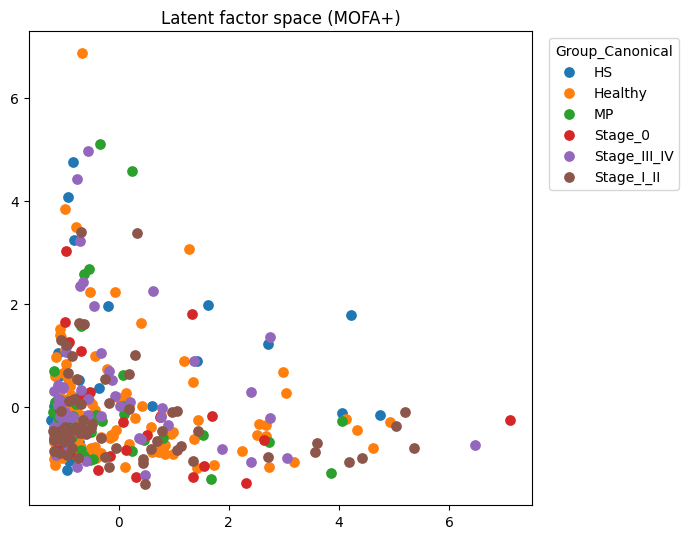

,Contrast,Feature_Block,Model,Status,N_Total,N_Features_Input,N_Features_Selected,CV_ROC_AUC_Mean,CV_ROC_AUC_SD,Holdout_ROC_AUC,Holdout_Average_Precision,Error
3,Healthy_vs_Stage_I_II,genera_plus_metabolomics,XGBoost,ok,196,2316,73.0,0.663961,0.122924,0.667279,0.513690,
5,Healthy_vs_Early_CRC,genera_plus_metabolomics,XGBoost,ok,223,2316,75.0,0.634541,0.090080,0.651042,0.600890,
4,Healthy_vs_Early_CRC,species_plus_metabolomics,XGBoost,ok,223,7386,75.0,0.658970,0.061551,0.615885,0.519109,
1,Healthy_vs_Stage_0,genera_plus_metabolomics,XGBoost,ok,154,2316,57.0,0.531487,0.135805,0.602679,0.392230,
0,Healthy_vs_Stage_0,species_plus_metabolomics,XGBoost,ok,154,7386,57.0,0.454646,0.106552,0.593750,0.369079,
2,Healthy_vs_Stage_I_II,species_plus_metabolomics,XGBoost,ok,196,7386,73.0,0.611271,0.060798,0.569853,0.467963,
8,Healthy_vs_Early_CRC,MOFA+,XGBoost,ok,223,10,NaN,0.478053,0.058724,0.395833,0.425128,
7,Healthy_vs_Stage_I_II,MOFA+,XGBoost,ok,196,10,NaN,0.461998,0.060686,0.391544,0.315595,
6,Healthy_vs_Stage_0,MOFA+,XGBoost,ok,154,10,NaN,0.339692,0.061342,0.290179,0.170654,


In [9]:
# Train MOFA+ when mofapy2 is available; otherwise use an explicitly labelled PCA fallback.
MOFA_N_FACTORS = 10
MOFA_TOP_GENERA = 60
MOFA_TOP_METABOLITES = 40
HAS_MOFAPY2 = ensure_optional_package("mofapy2", "mofapy2")

mofa_views = {
    "genera": genera_prep["scaled"].loc[:, genera_prep["scaled"].var().nlargest(min(MOFA_TOP_GENERA, genera_prep["scaled"].shape[1])).index],
    "metabolomics": metabolomics_prep["scaled"].loc[:, metabolomics_prep["scaled"].var().nlargest(min(MOFA_TOP_METABOLITES, metabolomics_prep["scaled"].shape[1])).index],
}


def pca_factor_fallback(reason):
    combined = pd.concat(
        [mofa_views["genera"].add_prefix("genera|"), mofa_views["metabolomics"].add_prefix("metabolite|")],
        axis=1,
    )
    n_factors = max(1, min(MOFA_N_FACTORS, combined.shape[0] - 1, combined.shape[1]))
    factors = PCA(n_components=n_factors, random_state=RANDOM_STATE).fit_transform(combined)
    frame = pd.DataFrame(factors, index=combined.index, columns=[f"Factor{i+1}" for i in range(n_factors)])
    return frame, "PCA_fallback_not_MOFA", reason


def train_mofa_factors():
    if not HAS_MOFAPY2:
        return pca_factor_fallback("mofapy2 package unavailable")
    try:
        from mofapy2.run.entry_point import entry_point

        sample_order = mofa_views["genera"].index
        if not sample_order.equals(mofa_views["metabolomics"].index):
            raise ValueError("MOFA views do not have the same sample order.")

        # Official mofapy2 matrix structure: views -> groups -> samples x features.
        data_matrix = [
            [mofa_views["genera"].to_numpy(dtype=float)],
            [mofa_views["metabolomics"].to_numpy(dtype=float)],
        ]
        ent = entry_point()
        ent.set_data_options(scale_groups=False, scale_views=False)
        ent.set_data_matrix(data_matrix)
        ent.set_model_options(
            factors=min(MOFA_N_FACTORS, len(sample_order) - 1),
            ard_factors=True,
            ard_weights=True,
            spikeslab_weights=True,
        )
        ent.set_train_options(iter=50 if FAST_MODE else 300, convergence_mode="fast", seed=RANDOM_STATE)
        ent.build()
        ent.run()

        expectation = ent.model.nodes["Z"].getExpectation()
        if isinstance(expectation, list):
            expectation = expectation[0]
        values = np.asarray(expectation, dtype=float)
        if values.shape[0] != len(sample_order) and values.ndim == 2 and values.shape[1] == len(sample_order):
            values = values.T
        if values.ndim != 2 or values.shape[0] != len(sample_order):
            raise ValueError(f"Unexpected MOFA factor shape: {values.shape}")
        factors = pd.DataFrame(values, index=sample_order, columns=[f"Factor{i+1}" for i in range(values.shape[1])])

        model_path = ML_DIR / "yachida_mofa_model.hdf5"
        try:
            ent.save(outfile=str(model_path), save_data=True)
        except TypeError:
            try:
                ent.save(str(model_path))
            except Exception as save_exc:
                print(f"[WARNING] MOFA factors were trained, but the HDF5 model could not be saved: {save_exc}")
        except Exception as save_exc:
            print(f"[WARNING] MOFA factors were trained, but the HDF5 model could not be saved: {save_exc}")
        return factors, "MOFA+", ""
    except Exception as exc:
        print(f"[WARNING] MOFA+ training failed; using labelled PCA fallback: {exc}")
        return pca_factor_fallback(str(exc))


mofa_factors, factor_method, factor_reason = train_mofa_factors()
mofa_factors.to_csv(ML_DIR / "latent_factors.csv")
pd.DataFrame([{"Factor_Method": factor_method, "Fallback_Reason": factor_reason}]).to_csv(
    ML_DIR / "latent_factor_method_status.csv", index=False
)

if mofa_factors.shape[1] >= 2:
    factor_plot = mofa_factors.iloc[:, :2].copy()
    factor_plot[GROUP_COL] = metadata.loc[factor_plot.index, GROUP_COL].astype(str)
    plt.figure(figsize=(7, 5.5))
    for group_name, group_frame in factor_plot.groupby(GROUP_COL, sort=True):
        plt.scatter(group_frame[factor_plot.columns[0]], group_frame[factor_plot.columns[1]], s=45, label=str(group_name))
    plt.legend(title=GROUP_COL, bbox_to_anchor=(1.02, 1), loc="upper left")
    plt.title(f"Latent factor space ({factor_method})")
    plt.tight_layout()
    plt.savefig(FIG_DIR / "latent_factor_space.png", dpi=250, bbox_inches="tight")
    plt.show()
    plt.close()

mofa_records = []
for contrast_name in EARLY_CONTRAST_NAMES:
    X_sub, y = get_contrast_data(mofa_factors, contrast_name)
    counts = y.value_counts()
    if len(counts) != 2 or counts.min() < 4:
        continue
    X_train, X_test, y_train, y_test = train_test_split(
        X_sub, y, test_size=TEST_SIZE, stratify=y, random_state=RANDOM_STATE
    )
    cv_splits = min(OUTER_CV_SPLITS, int(counts.min()))
    cv = StratifiedKFold(n_splits=cv_splits, shuffle=True, random_state=RANDOM_STATE)
    neg = int((y_train == 0).sum())
    pos = int((y_train == 1).sum())
    model = make_xgb_pipeline(k=X_sub.shape[1], scale_pos_weight=neg / max(pos, 1))
    try:
        cv_scores = safe_cv_scores(model, X_sub, y, cv)
        model.fit(X_train, y_train)
        y_score = model.predict_proba(X_test)[:, 1]
        mofa_records.append({
            "Contrast": contrast_name,
            "Feature_Block": factor_method,
            "Model": "XGBoost" if HAS_XGBOOST else "GradientBoosting_fallback",
            "Status": "ok",
            "N_Total": len(y),
            "N_Features_Input": X_sub.shape[1],
            "CV_ROC_AUC_Mean": float(np.nanmean(cv_scores)) if np.isfinite(cv_scores).any() else np.nan,
            "CV_ROC_AUC_SD": float(np.nanstd(cv_scores)) if np.isfinite(cv_scores).any() else np.nan,
            "Holdout_ROC_AUC": float(roc_auc_score(y_test, y_score)),
            "Holdout_Average_Precision": float(average_precision_score(y_test, y_score)),
            "Error": "",
        })
    except Exception as exc:
        mofa_records.append({
            "Contrast": contrast_name,
            "Feature_Block": factor_method,
            "Model": "XGBoost" if HAS_XGBOOST else "GradientBoosting_fallback",
            "Status": "failed",
            "N_Total": len(y),
            "N_Features_Input": X_sub.shape[1],
            "CV_ROC_AUC_Mean": np.nan,
            "CV_ROC_AUC_SD": np.nan,
            "Holdout_ROC_AUC": np.nan,
            "Holdout_Average_Precision": np.nan,
            "Error": str(exc),
        })
        print(f"[WARNING] Latent-factor classifier failed for {contrast_name}: {exc}")

mofa_xgb_summary = pd.DataFrame(mofa_records)
mofa_xgb_summary.to_csv(ML_DIR / "latent_factor_xgboost_summary.csv", index=False)
model_comparison = pd.concat([direct_xgb_summary, mofa_xgb_summary], ignore_index=True, sort=False)
model_comparison.to_csv(ML_DIR / "direct_vs_latent_factor_model_comparison.csv", index=False)
display(model_comparison.sort_values("Holdout_ROC_AUC", ascending=False, na_position="last"))

Contrast: Healthy_vs_Early_CRC
Feature block: genera_plus_metabolomics
Class counts: {0: 127, 1: 96}
Class 0: Healthy
Class 1: Early CRC
Selected feature count: 75
Holdout ROC AUC: 0.651
Holdout Average Precision: 0.601

Top SHAP-ranked genera and metabolites:


,Rank,Feature,Mean_Absolute_SHAP,Feature_Type
0,1,genera|d__Bacteria;p__Firmicutes_A;c__Clostrid...,0.300629,Genus
1,2,genera|d__Bacteria;p__Fusobacteriota;c__Fusoba...,0.255602,Genus
2,3,metabolite|C02567_N1-Acetylspermine,0.243954,Metabolite
3,4,genera|d__Bacteria;p__Bacteroidota;c__Bacteroi...,0.243100,Genus
4,5,genera|d__Bacteria;p__Bacteroidota;c__Bacteroi...,0.234563,Genus
5,6,genera|d__Bacteria;p__Proteobacteria;c__Gammap...,0.212379,Genus
6,7,genera|d__Bacteria;p__Firmicutes_A;c__Clostrid...,0.185183,Genus
7,8,genera|d__Bacteria;p__Bacteroidota;c__Bacteroi...,0.182177,Genus
8,9,metabolite|C06423_Octanoate,0.159735,Metabolite
9,10,genera|d__Bacteria;p__Bacteroidota;c__Bacteroi...,0.153924,Genus


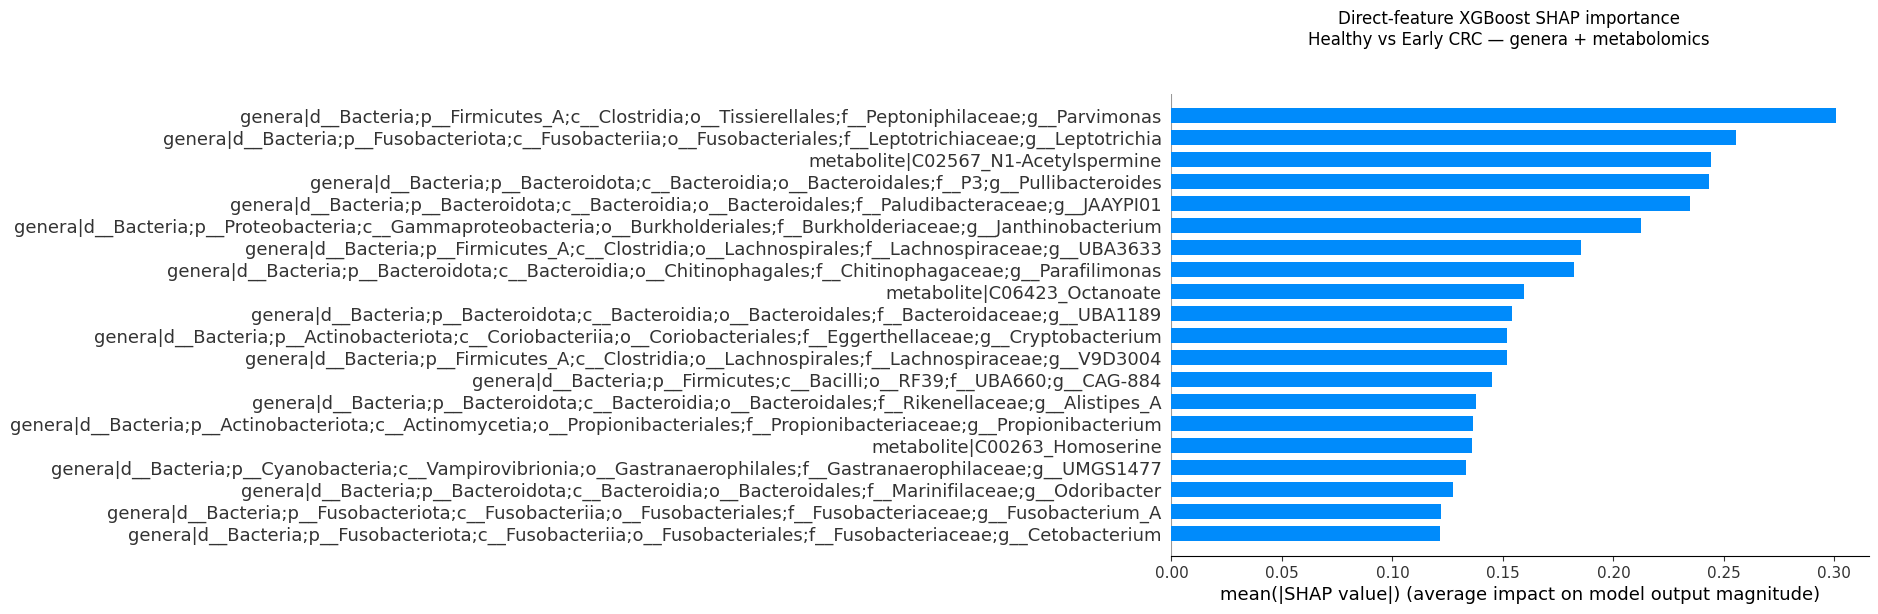

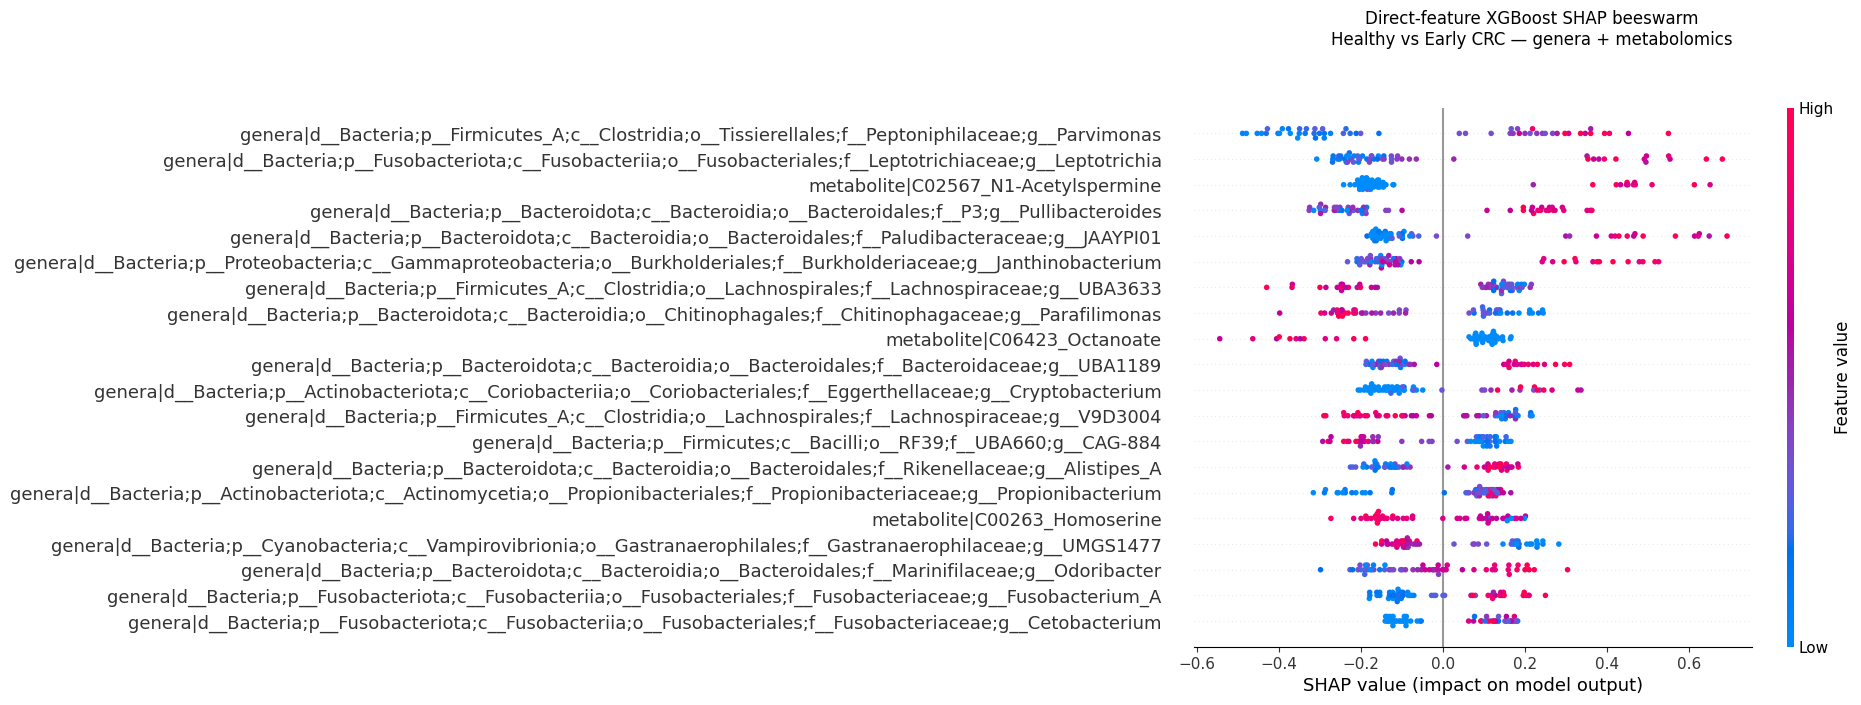

In [11]:
# XGBoost SHAP analysis

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score, average_precision_score



SHAP_CONTRAST = "Healthy_vs_Early_CRC"
SHAP_BLOCK = "genera_plus_metabolomics"
SHAP_TOP_N = 20


if SHAP_CONTRAST not in ACTIVE_CONTRASTS:
    raise KeyError(
        f"{SHAP_CONTRAST} is not available. "
        f"Available contrasts: {list(ACTIVE_CONTRASTS)}"
    )

if SHAP_BLOCK not in ml_blocks:
    raise KeyError(
        f"{SHAP_BLOCK} is not available. "
        f"Available feature blocks: {list(ml_blocks)}"
    )

if not HAS_XGBOOST:
    raise RuntimeError(
        "This cell requires XGBoost, but XGBoost is unavailable."
    )


HAS_SHAP_EXPLICIT = ensure_optional_package("shap", "shap")

if not HAS_SHAP_EXPLICIT:
    raise RuntimeError(
        "The shap package could not be installed or imported."
    )

import shap


# Prepare Healthy vs Early CRC data


X_all, y_all = get_contrast_data(
    ml_blocks[SHAP_BLOCK],
    SHAP_CONTRAST
)

class_counts = y_all.value_counts().sort_index()

print("Contrast:", SHAP_CONTRAST)
print("Feature block:", SHAP_BLOCK)
print("Class counts:", class_counts.to_dict())
print("Class 0: Healthy")
print("Class 1: Early CRC")


if len(class_counts) != 2 or class_counts.min() < 4:
    raise ValueError(
        f"Insufficient samples for stratified analysis: "
        f"{class_counts.to_dict()}"
    )


# Use the same train/test design as the new notebook

X_train, X_test, y_train, y_test = train_test_split(
    X_all,
    y_all,
    test_size=TEST_SIZE,
    stratify=y_all,
    random_state=RANDOM_STATE
)

k = choose_k(
    SHAP_BLOCK,
    X_all.shape[1],
    X_train.shape[0]
)

negative_n = int((y_train == 0).sum())
positive_n = int((y_train == 1).sum())

scale_pos_weight = negative_n / max(positive_n, 1)


# Fit the direct-feature XGBoost model


shap_xgb_pipeline = make_xgb_pipeline(
    k=k,
    scale_pos_weight=scale_pos_weight
)

shap_xgb_pipeline.fit(X_train, y_train)

test_probability = shap_xgb_pipeline.predict_proba(X_test)[:, 1]

test_auc = roc_auc_score(y_test, test_probability)
test_ap = average_precision_score(y_test, test_probability)

print(f"Selected feature count: {k}")
print(f"Holdout ROC AUC: {test_auc:.3f}")
print(f"Holdout Average Precision: {test_ap:.3f}")


# Transform the test set with the fitted preprocessing steps

X_test_imputed = shap_xgb_pipeline.named_steps[
    "imputer"
].transform(X_test)

X_test_selected = shap_xgb_pipeline.named_steps[
    "feature_select"
].transform(X_test_imputed)

selected_feature_names = selected_feature_names(
    shap_xgb_pipeline,
    X_train.columns
)

X_test_shap = pd.DataFrame(
    X_test_selected,
    index=X_test.index,
    columns=selected_feature_names
)

xgb_estimator = shap_xgb_pipeline.named_steps["xgb"]

# 7. Compute SHAP values with compatibility handling

try:
    shap_explainer = shap.TreeExplainer(xgb_estimator)
    raw_shap_values = shap_explainer.shap_values(X_test_shap)

except Exception:
    # Compatibility fallback for newer SHAP/XGBoost combinations
    X_train_imputed = shap_xgb_pipeline.named_steps[
        "imputer"
    ].transform(X_train)

    X_train_selected = shap_xgb_pipeline.named_steps[
        "feature_select"
    ].transform(X_train_imputed)

    X_train_shap = pd.DataFrame(
        X_train_selected,
        index=X_train.index,
        columns=selected_feature_names
    )

    shap_explainer = shap.Explainer(
        xgb_estimator,
        X_train_shap
    )

    raw_shap_values = shap_explainer(X_test_shap)


if hasattr(raw_shap_values, "values"):
    shap_values = np.asarray(raw_shap_values.values)

elif isinstance(raw_shap_values, list):

    shap_values = np.asarray(raw_shap_values[-1])

else:
    shap_values = np.asarray(raw_shap_values)


if shap_values.ndim == 3:

    if (
        shap_values.shape[0] == X_test_shap.shape[0]
        and shap_values.shape[1] == X_test_shap.shape[1]
    ):
        shap_values = shap_values[:, :, -1]

    elif (
        shap_values.shape[1] == X_test_shap.shape[0]
        and shap_values.shape[2] == X_test_shap.shape[1]
    ):
        shap_values = shap_values[-1, :, :]

    else:
        raise ValueError(
            f"Unsupported SHAP output shape: {shap_values.shape}"
        )



if shap_values.shape == (
    X_test_shap.shape[1],
    X_test_shap.shape[0]
):
    shap_values = shap_values.T


if shap_values.shape != X_test_shap.shape:
    raise ValueError(
        f"SHAP matrix shape {shap_values.shape} does not match "
        f"test matrix shape {X_test_shap.shape}."
    )


# Rank selected genera/metabolites by mean absolute SHAP

shap_rank = pd.DataFrame({
    "Feature": X_test_shap.columns,
    "Mean_Absolute_SHAP": np.abs(shap_values).mean(axis=0)
})

shap_rank = (
    shap_rank
    .sort_values("Mean_Absolute_SHAP", ascending=False)
    .reset_index(drop=True)
)

shap_rank.insert(
    0,
    "Rank",
    np.arange(1, len(shap_rank) + 1)
)

shap_rank["Feature_Type"] = np.where(
    shap_rank["Feature"].str.startswith("genera|"),
    "Genus",
    np.where(
        shap_rank["Feature"].str.startswith("metabolite|"),
        "Metabolite",
        "Other"
    )
)

print("\nTop SHAP-ranked genera and metabolites:")
display(shap_rank.head(SHAP_TOP_N))




shap.summary_plot(
    shap_values,
    X_test_shap,
    plot_type="bar",
    max_display=min(SHAP_TOP_N, X_test_shap.shape[1]),
    show=False
)

figure = plt.gcf()
figure.set_size_inches(9, 6)

figure.suptitle(
    "Direct-feature XGBoost SHAP importance\n"
    "Healthy vs Early CRC — genera + metabolomics",
    y=1.02
)

figure.tight_layout()
plt.show()
plt.close(figure)


# SHAP beeswarm plot

shap.summary_plot(
    shap_values,
    X_test_shap,
    max_display=min(SHAP_TOP_N, X_test_shap.shape[1]),
    show=False
)

figure = plt.gcf()
figure.set_size_inches(9, 7)

figure.suptitle(
    "Direct-feature XGBoost SHAP beeswarm\n"
    "Healthy vs Early CRC — genera + metabolomics",
    y=1.02
)

figure.tight_layout()
plt.show()
plt.close(figure)

## 8. Package outputs

In [10]:
# organize output.
archive_path = Path(shutil.make_archive(str(OUT_DIR), "zip", root_dir=OUT_DIR))
print(f"Created output archive: {archive_path}")
if IN_COLAB:
    print("Download it from the Colab file browser, or run:")
    print(f"from google.colab import files; files.download(r'{archive_path}')")

Created output archive: /content/01_Yachida_MOFA_XGBoost_results.zip
Download it from the Colab file browser, or run:
from google.colab import files; files.download(r'/content/01_Yachida_MOFA_XGBoost_results.zip')
